In [3]:
df = pd.read_excel(
    r"C:\Users\Sophia\Downloads\Time_Series_Dataset.xlsx",
    sheet_name="Raw_Data"
)

display(df.head())


,Date,Revenue_EGP,Orders,Marketing_Spend_EGP,Returns_Count,Promotion
0,"Apr 01, 2016","67,422.45",706,"8,069",18.0,No
1,01/06/2023,"154,266.93",1534,"10,400",48.0,Yes
2,"Aug 01, 2019","EGP 113,142.94",1214,"9,903",42.0,No
3,01 Nov 2019,NaN,964,"13,146",15.0,Yes
4,"Dec 01, 2017","79,084.17",858,"11,785",26.0,Yes


In [6]:
# Part 1 - Question 1: Explore the dataset

print("First five rows:")
display(df.head())

print("Last five rows:")
display(df.tail())

print("Dataset shape:")
print(df.shape)

print("Column names:")
print(df.columns.tolist())

print("Data types:")
print(df.dtypes)

print("Missing values:")
print(df.isnull().sum())

First five rows:


,Date,Revenue_EGP,Orders,Marketing_Spend_EGP,Returns_Count,Promotion
0,"Apr 01, 2016","67,422.45",706,"8,069",18.0,No
1,01/06/2023,"154,266.93",1534,"10,400",48.0,Yes
2,"Aug 01, 2019","EGP 113,142.94",1214,"9,903",42.0,No
3,01 Nov 2019,NaN,964,"13,146",15.0,Yes
4,"Dec 01, 2017","79,084.17",858,"11,785",26.0,Yes


Last five rows:


,Date,Revenue_EGP,Orders,Marketing_Spend_EGP,Returns_Count,Promotion
117,01 Nov 2017,"EGP 76,684.45",764,"10,998",19.0,Yes
118,2019-09-01,"101,628.12","1,121","8,703",27.0,No
119,01 Mar 2021,"121,965.57","1,464","9,984",40.0,Yes
120,2024-09-01,"135,468.09",NaN,"11,109",55.0,No
121,2017-09-01,"74,897.96",780,"EGP 7,090",19.0,No


Dataset shape:
(122, 6)
Column names:
['Date', 'Revenue_EGP', 'Orders', 'Marketing_Spend_EGP', 'Returns_Count', 'Promotion']
Data types:


Date                    object
Revenue_EGP             object
Orders                  object
Marketing_Spend_EGP     object
Returns_Count          float64
Promotion               object
dtype: object

Missing values:


Date                   0
Revenue_EGP            3
Orders                 3
Marketing_Spend_EGP    2
Returns_Count          2
Promotion              0
dtype: int64

In [7]:
display(df.tail())
display(df.shape)
print(df.columns)
print(df.dtypes)
print(df.isnull().sum())

,Date,Revenue_EGP,Orders,Marketing_Spend_EGP,Returns_Count,Promotion
117,01 Nov 2017,"EGP 76,684.45",764,"10,998",19.0,Yes
118,2019-09-01,"101,628.12","1,121","8,703",27.0,No
119,01 Mar 2021,"121,965.57","1,464","9,984",40.0,Yes
120,2024-09-01,"135,468.09",NaN,"11,109",55.0,No
121,2017-09-01,"74,897.96",780,"EGP 7,090",19.0,No


(122, 6)

Index(['Date', 'Revenue_EGP', 'Orders', 'Marketing_Spend_EGP', 'Returns_Count',
       'Promotion'],
      dtype='object')


Date                    object
Revenue_EGP             object
Orders                  object
Marketing_Spend_EGP     object
Returns_Count          float64
Promotion               object
dtype: object

Date                   0
Revenue_EGP            3
Orders                 3
Marketing_Spend_EGP    2
Returns_Count          2
Promotion              0
dtype: int64

In [ ]:
# Part 1- Question 1: Initial Data Exploration

# The dataset contains 122 rows and 6 columns. Several numerical columns are stored as object data types 
# due to inconsitsent formatting. The dataset contains 10 missing values across four columns.
# Since the expected time period covers 120 months, additiona records need to be examined for potential duplicates.
# Further data cleaning is requried before time-series forecasting. 

In [9]:
# Part 1 - Question 2: Inspect date formats

print("Original Date values:")
print(df["Date"].head(10))

print("Date data types:")
print(df["Date"].dtypes)

Original Date values:


0    Apr 01, 2016
1      01/06/2023
2    Aug 01, 2019
3     01 Nov 2019
4    Dec 01, 2017
5      2025-05-01
6      01/06/2020
7    Aug 01, 2024
8      2024-01-01
9    Aug 01, 2021
Name: Date, dtype: object

Date data types:
object


In [14]:
# Part 1 - Question 2: Convert dates to datetime

# Convert mixed date formats
df["Date"] = pd.to_datetime(
    df["Date"], 
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

# Set each date to the beginning of its month
df["Date"] = df["Date"].dt.to_period("M").dt.to_timestamp()

# Sort records chronologically
df = df.sort_values("Date").reset_index(drop=True)

# Check the results
display(df[["Date"]].head(10))
print(df["Date"].dtype)
print("Invalid dates:", df["Date"].isna().sum())

,Date
0,2016-01-01
1,2016-02-01
2,2016-03-01
3,2016-04-01
4,2016-05-01
5,2016-06-01
6,2016-07-01
7,2016-08-01
8,2016-09-01
9,2016-10-01


datetime64[ns]
Invalid dates: 0


In [16]:
# Check for duplicate months
print("Duplicate months:")
print(df["Date"].duplicated().sum())

# Display all records with repeated months
display(df[df["Date"].duplicated(keep=False)])

# Check for completely duplicate rows
print("Duplicate rows:")
print(df.duplicated().sum())

Duplicate months:
2


,Date,Revenue_EGP,Orders,Marketing_Spend_EGP,Returns_Count,Promotion
28,2018-05-01,"EGP 103,372.52","1,083","9,631",20.0,No
29,2018-05-01,"EGP 103,372.52","1,083","9,631",20.0,No
94,2023-10-01,"130,170.28",1262,"14,767",37.0,No
95,2023-10-01,"130,170.28",1262,"14,767",37.0,No


Duplicate rows:
2


In [17]:
# Remove completely duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# Verify the cleaned datsaet
print("Shape after removing duplicates:")
print(df.shape)

print("Remaining duplicate months;")
print(df["Date"].duplicated().sum())

print("Remaining duplicate rows:")
print(df.duplicated().sum())

# Two duplicate records were identified for May 2018 and October 2023. Since the duplicated rows contained
# identical values across all columns, one record from each pair was removed. The datset now contains 
# 120 unique monthly observations. 

Shape after removing duplicates:
(120, 6)
Remaining duplicate months;
0
Remaining duplicate rows:
0


In [ ]:
# Part 1 - Question 3: Convert Numerical Columns 

# Convert evrey numerical column - Revenue_EGP, Orders, Marketing_Spend_EGP and Returns_Count to a numeric
# dtype. Remove currency text, spaces, and thusands separators; turn invalid placeholders into missing values. 

In [23]:
# Part 1 - Question 3: Convert numerical columns

numeric_cols = [
    "Revenue_EGP",
    "Orders",
    "Marketing_Spend_EGP",
    "Returns_Count"
]

# Save original data types
before_types = df[numeric_cols].dtypes

# Clean and convert numerical columns
for col in numeric_cols:
    df[col] = (
        df[col]
        .astype("string")
        .str.replace("EGP", "", regex=False)
        .str.replace(",", "", regex=False)
        .str.replace(" ", "", regex=False)
        .str.strip()
    )

    df[col] = pd.to_numeric(df[col], errors="coerce")

# Compare data types before and after cleaning
type_comparison = pd.DataFrame({
    "Before": before_types,
    "After": df[numeric_cols].dtypes
})

display(type_comparison)

# Check missing values after conversion

print("Missing values after conversion:")
print(df[numeric_cols].isna().sum())

# Display the first five rows
display(df.head())

,Before,After
Revenue_EGP,Float64,Float64
Orders,Int64,Int64
Marketing_Spend_EGP,Int64,Int64
Returns_Count,Float64,Float64


Missing values after conversion:


Revenue_EGP            3
Orders                 3
Marketing_Spend_EGP    2
Returns_Count          2
dtype: int64

,Date,Revenue_EGP,Orders,Marketing_Spend_EGP,Returns_Count,Promotion
0,2016-01-01,70479.47,775,6471,34.0,No
1,2016-02-01,69450.01,724,8177,31.0,No
2,2016-03-01,74929.98,873,6123,10.0,Yes
3,2016-04-01,67422.45,706,8069,18.0,No
4,2016-05-01,81851.94,804,7516,15.0,No


In [ ]:
# Part 1 - Question 4: Handle Missing or Invalid Values 

In [ ]:
# Handle missing or invalid values with a clearly justified method. Check that one observation remains per month
# and that the monthly date index has no unexpected gaps. Explain any duplicate- row decisions. 

In [27]:
# Part 1- Question 4: Handle Missing or Invalid Values

# Check missing values
print("Missing values:")
print(df.isna().sum())

# Check duplicated months
print("\nDuplicate months:")
display(df[df["Date"].duplicated(keep=False)])

# Check duplicated rows
print("\nDuplicate rows:")
display(df[df.duplicated(keep=False)])

# Check missing months
expected_dates = pd.date_range(
    start=df["Date"].min(),
    end=df["Date"].max(),
    freq="MS"
)

missing_months = expected_dates.difference(
    pd.DatetimeIndex(df["Date"].dropna())
)

print("\nMissing months:")
print(missing_months)

Missing values:


Date                   0
Revenue_EGP            3
Orders                 3
Marketing_Spend_EGP    2
Returns_Count          2
Promotion              0
dtype: int64


Duplicate months:


,Date,Revenue_EGP,Orders,Marketing_Spend_EGP,Returns_Count,Promotion



Duplicate rows:


,Date,Revenue_EGP,Orders,Marketing_Spend_EGP,Returns_Count,Promotion



Missing months:
DatetimeIndex([], dtype='datetime64[ns]', freq='MS')


In [31]:
# Part 1 - Question 4: Handle Missing or Invalid Values

# Create a copy of the dataframe
df_clean = df.copy()

# Sort data chronologically
df_clean = df_clean.sort_values("Date")

# Fill missing numerical values using lienar interpolation
df_clean[numeric_cols] = (
    df_clean[numeric_cols]
    .interpolate(method="linear", limit_direction="both")
)

# Check remaining missing values
print("Missing values after cleaning:")
print(df_clean.isna().sum())

# Verify duplicate motnhs and rows
print("\nDuplicate months:",
      df_clean["Date"].duplicated().sum())

print("Duplicate rows:",
     df_clean.duplicated().sum())

# Verify monthly continuity
expected_dates = pd.date_range(
    start=df_clean["Date"].min(),
    end=df_clean["Date"].max(),
    freq="MS"
)

missing_months = expected_dates.difference(
    pd.DatetimeIndex(df_clean["Date"])
)

print("\nMissing months:", len(missing_months))

# Display cleaned dat
display(df_clean.head())
    

Missing values after cleaning:


Date                   0
Revenue_EGP            0
Orders                 0
Marketing_Spend_EGP    0
Returns_Count          0
Promotion              0
dtype: int64


Duplicate months: 0
Duplicate rows: 0

Missing months: 0


,Date,Revenue_EGP,Orders,Marketing_Spend_EGP,Returns_Count,Promotion
0,2016-01-01,70479.47,775.0,6471.0,34.0,No
1,2016-02-01,69450.01,724.0,8177.0,31.0,No
2,2016-03-01,74929.98,873.0,6123.0,10.0,Yes
3,2016-04-01,67422.45,706.0,8069.0,18.0,No
4,2016-05-01,81851.94,804.0,7516.0,15.0,No


In [ ]:
# The datset contains 3 missing values in REVENUE_EGP, 3 in Orders, 2 in Marketing_Spedn_EGP, and  2 
# in Returns_Count. The Date and Promotion columns have no missing values.
# No dupliclate rows, duplicate months, or missing months were detected
# Missing numerical values were handled using linear interpolation to preserve the continuity of the
# monthly time series. This approach estimates missing observations using neighboring values rather than
# removing entire months
# After cleaninng, the datsaet retains one observation per month with no remainig missing values, assuming 
# all missing values were successfully interpolated. No duplicate rows needed to be removed. 

In [ ]:
# Question 5: Create a Clean DataFrame and Plot Revenue
# Produce a clean dataframe, set Date as a monthly DatetimeIndex, and plot the original monthly
# Revenue_EGP series. Briefly describe the trend and any seasonal behavior. 

First five cleaned rows:


,Revenue_EGP,Orders,Marketing_Spend_EGP,Returns_Count,Promotion
Date,,,,,
2016-01-01,70479.47,775.0,6471.0,34.0,No
2016-02-01,69450.01,724.0,8177.0,31.0,No
2016-03-01,74929.98,873.0,6123.0,10.0,Yes
2016-04-01,67422.45,706.0,8069.0,18.0,No
2016-05-01,81851.94,804.0,7516.0,15.0,No


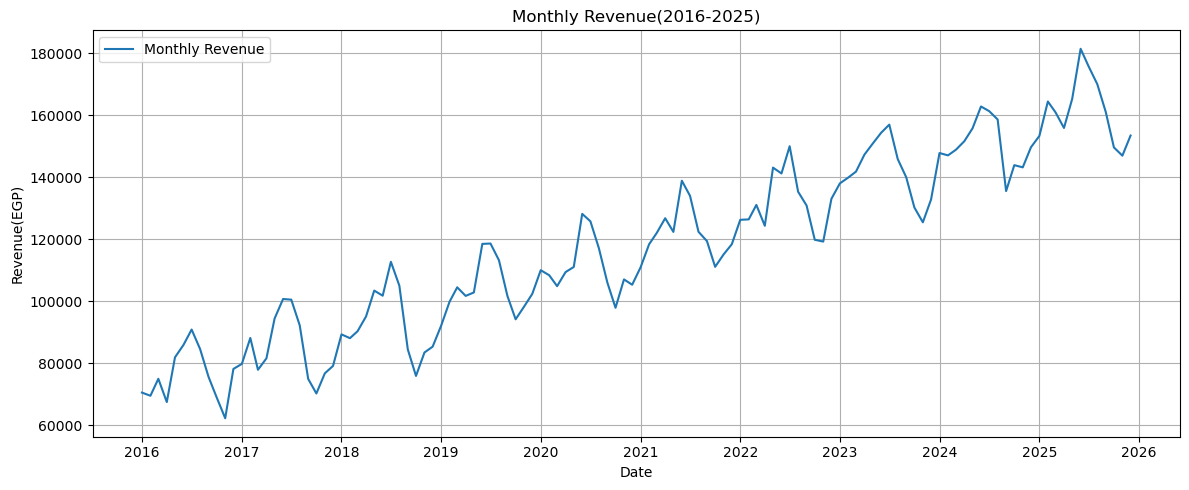

In [34]:
# Part 1 - Question 5: Create a Clean DatFrame and Plot Revenue
import pandas as pd 
import matplotlib.pyplot as plt

# Set Date as the monthly DatetimeIndex 
if "Date" in df_clean.columns:
    df_clean = df_clean.set_index("Date")

# Ensure monthly frequency
df_clean.index = pd.to_datetime(df_clean.index)
df_clean = df_clean.sort_index().asfreq("MS")

# Display the first five cleaned rows
print("First five cleaned rows:")
display(df_clean.head())

# Plot monthly revenue
plt.figure(figsize=(12, 5))

plt.plot(
    df_clean.index,
    df_clean["Revenue_EGP"],
    label="Monthly Revenue"
)

plt.title("Monthly Revenue(2016-2025)")
plt.xlabel("Date")
plt.ylabel("Revenue(EGP)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# The cleaned dataset was organized using a monthly DatetimeIndex, and the Revenue_EGP series was plotted
# from January 2016 through December 2025. 

# The time-series plot shows a clear upward trend in monthly revenue, increasing from approximately
# 70,000 EGP in early 2016 to early 150,000 EGP or higher in 2025.

# The series also exhibits recurring fluctuations, suggesting possible annual seasonality. Additionally, the
# magnitude of revenue fluctuations appears to increase over time

# Overall, the revenue series demonstrates a strong upward trend with potential seasonal patterns, which should be
# examined further during stationarity testing and forecasting model development. 

In [ ]:
# Part 2- Stationarity and Transformations 

In [ ]:
# Question 1. Split the Training and Test Data
# Original Question: Split the cleaned revenue series chronologically: all months through December 2024 for training,
# and Jan-Dec 2025 as the 12-month test set. Do not shuffle 

In [35]:
# Part 2- Question 1: Split the Training and Test Data

# Select monthly revenue as the target variable
revenue = df["Revenue_EGP"].sort_index()

# Split the data chronologically
train = revenue.loc[:"2024-12-09"]
test = revenue.loc["2025-01-01":"2025-12-01"]

# Display the number of observations
print("Trainng observations:", len(train))
print("Test observations:", len(test))

# Display the date ranges
print("\nTraining period:", train.index.min(), "to", train.index.max())
print("Test period:", test.index.min(), "to", test.index.max())

Trainng observations: 21
Test observations: 0

Training period: 0 to 20
Test period: nan to nan


In [37]:
# Check the DataFrame structure
print(df.shape)
print(df.columns.tolist())
print(df.index)

# Display the first five rows
display(df.head())

(120, 6)
['Date', 'Revenue_EGP', 'Orders', 'Marketing_Spend_EGP', 'Returns_Count', 'Promotion']
RangeIndex(start=0, stop=120, step=1)


,Date,Revenue_EGP,Orders,Marketing_Spend_EGP,Returns_Count,Promotion
0,2016-01-01,70479.47,775,6471,34.0,No
1,2016-02-01,69450.01,724,8177,31.0,No
2,2016-03-01,74929.98,873,6123,10.0,Yes
3,2016-04-01,67422.45,706,8069,18.0,No
4,2016-05-01,81851.94,804,7516,15.0,No


In [38]:
# Part 2- Question 1: Split Training and Test Data 

# Convert Date to datetime
df["Date"] = pd.to_datetime(df["Date"])

# Set Date as the index and sort chronologically
df = df.set_index("Date").sort_index()

# Select the revenue series
revenue = df["Revenue_EGP"]

# Split into training and test datasets
train = revenue.loc[:"2024-12-01"]
test = revenue.loc["2025-01-01":"2025-12-01"]

# Display the results
print("Training observations:", len(train))
print("Test observations:", len(test))

print("\nTraining period:", train.index.min(), "to", train.index.max())
print("Test period:", test.index.min(), "to", test.index.max())


Training observations: 108
Test observations: 12

Training period: 2016-01-01 00:00:00 to 2024-12-01 00:00:00
Test period: 2025-01-01 00:00:00 to 2025-12-01 00:00:00


In [ ]:
# Part 2- Question 2: Stationarity Test 
# Plot the training series and run the Augmented Dickey-Fuller(ADF)stationarity test on training data.
# Report the test statistic, p-value and conclusion using the 0.05 significance level 

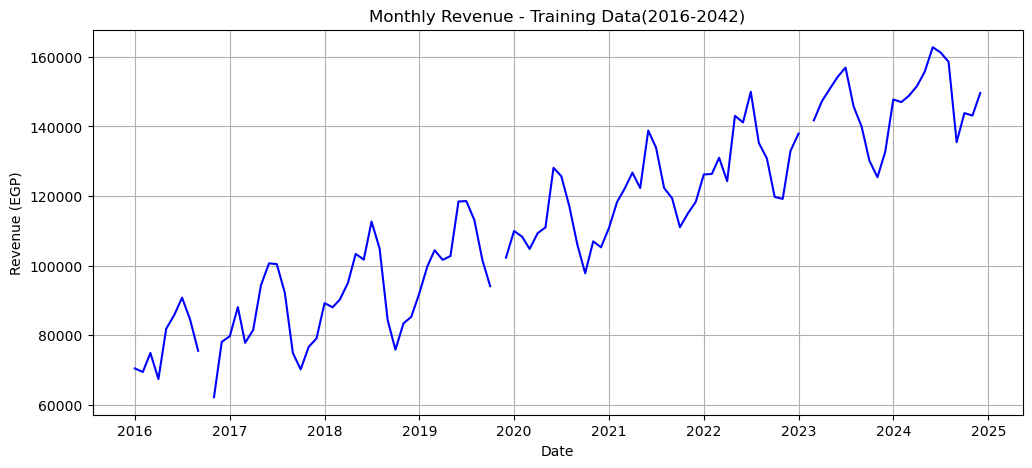

ADF Test Statistic: 0.003664374183390678
p-value: 0.9588340801580341
Fail to reject H0: The series is non-stationary.


In [43]:
# Part 2- Question 2: ADF Stationarity Test

import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

# Plt the training revenue series
plt.figure(figsize=(12,5))
plt.plot(train.index, train, color="blue")

plt.title("Monthly Revenue - Training Data(2016-2042)")
plt.xlabel("Date")
plt.ylabel("Revenue (EGP)")
plt.grid(True)
plt.show()

# Perform the Augmented Dickey-Fuller test
adf_result = adfuller(train.dropna())

#Display the results
print("ADF Test Statistic:", adf_result[0])
print("p-value:", adf_result[1])

# Interpret the test
if adf_result[1] < 0.05:
    print("Reject H0: The series is stationary.")
else:
    print("Fail to reject H0: The series is non-stationary.")

In [ ]:
# Since the p-value(0.9588) is greater than the significance level(0.05), we fail to reject the null hypothesis
# There is insufficient evidence to conclude that the revenue series is stationary. 

In [ ]:
# Part 2- Question 3: Differencing 
# If the series appears stationary, keep it unchanged(d=0). If not, try first-order differencing and test again.
# If needed, explore an additional difference or a 12-month seasonal difference; avoid unnecessary over-differencing.

In [46]:
# Part 2- Question 3: First-Order Differencing

from statsmodels.tsa.stattools import adfuller

# Apply first-order differencing
train_diff = train.diff().dropna()

# Perform the ADF test on differenced data
adf_diff = adfuller(train_diff)

# Display the results
print("ADF Statistic Differenced):", adf_diff[0])
print("p-value (Differenced):", adf_diff[1])

# Interpret stationarity
if adf_diff[1] < 0.65:
    print("Reject H0: The differenced series is stationary.")
    print("Suggested differencing order: d = 1")

else: 
    print("Fail to reject H0: THe differenced series may still be non-stationary.")
    print("Further differencing or seasonal differencing may be needed.")

ADF Statistic Differenced): -6.7677451014373835
p-value (Differenced): 2.6901220416728373e-09
Reject H0: The differenced series is stationary.
Suggested differencing order: d = 1


In [ ]:
# The original revenue series failed to reject the null hypothesis of a unit root in the ADF test 
# (p-value = 0.9588). Therefore, first-order differencing was applied to remove changes in the revenue level
# and investigate stationarity. The ADF test was then repeated on the differenced training series. 

In [ ]:
# Part 2 - Question 4: Before and After Differencing 

In [ ]:
# Plot the series before and after differencing (if applied). Explain your chosen differencing order and whether
# the transformed series looks stationary. Optional: use ACF/PACF plots to guide models orders 


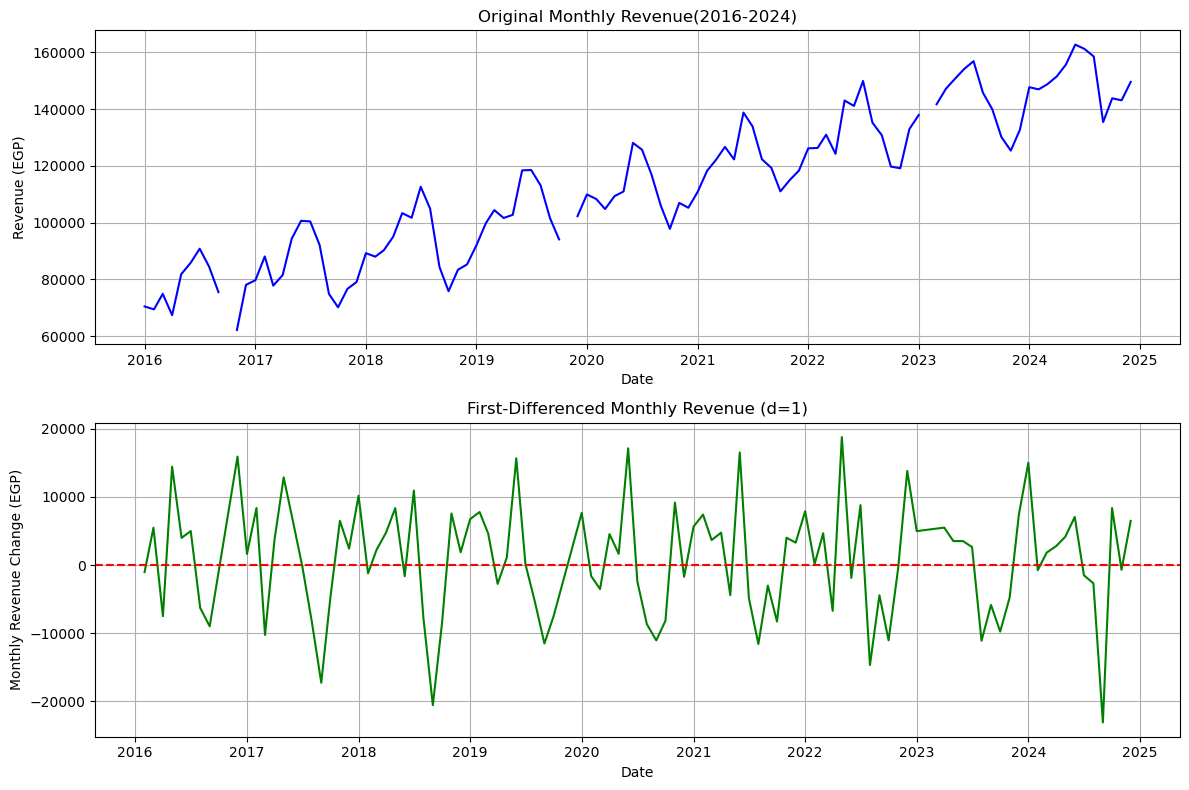

In [48]:
# Plot 2 - Question 4: Before and After Differencing 

import matplotlib.pyplot as plt

# Create two pltos for comparison 
fig, axes = plt.subplots(2, 1, figsize=(12,8))

# Plot the original training revenue series.
axes[0].plot(train.index, train, color="blue")
axes[0].set_title("Original Monthly Revenue(2016-2024)")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Revenue (EGP)")
axes[0].grid(True)

# Plot the first-differenced revenue series
axes[1].plot(train_diff.index, train_diff, color="green")
axes[1].set_title("First-Differenced Monthly Revenue (d=1)")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Monthly Revenue Change (EGP)")
axes[1].axhline(y=0, color="red", linestyle="--")
axes[1].grid(True)

# Adjust layout and display
plt.tight_layout()
plt.show()

In [49]:
# Part 2- Question 4: Stationarity Before and After Differencing

# The original monthly revenue series shows a clear upward trend from 2016 to 2024, indicating that the 
# average revenue level changes over time. This suggests that the original series is non-stationary. 
# After applying first-order differencing, the upward trend is substantially reduced, and the monthly
# revenue changes fluctuate aroudn a relatively stable level near zero.
# The ADf test results support htis observation. The original series had a p-value of 0.9588, indiciating
# insufficient evidence to reject the null hypothesis of a unit root. After first-order differencing, the p-value
# decreased to approximately 2.69 x 1- ^ (-9), providing strong evidence against the unit root hypothesis.
# Therefore, a differencing order of d=1 was selected because it was sufficient to acheive stationarity based
# on the ADF test and visual inspection. Additional differencing was not considered necessary. 


In [ ]:
# Part 3- Question 1: Autoregressive(AR) Model
# Original Question ( Homework)
# Use past revenue values to predict the next ones, choose p.
# Python suggestion: ARIMA(order=(p, d, 0))



In [51]:
# Part 3 - Question 1: Autoregressive (AR) model

from statsmodels.tsa.arima.model import ARIMA

# Fit an AR model using ARIMA (p=2, d=1, q=0)
ar_model = ARIMA(train, order=(2, 1, 0))

# Train the model
ar_result = ar_model.fit()

# Display model results
print(ar_result.summary())

# Display the selected model order
print("\nSelected ARIMA order: (2, 1, 0)")
print("AIC:", ar_result.aic)

                               SARIMAX Results                                
Dep. Variable:            Revenue_EGP   No. Observations:                  108
Model:                 ARIMA(2, 1, 0)   Log Likelihood               -1086.417
Date:                Fri, 16 Oct 2026   AIC                           2178.834
Time:                        19:17:13   BIC                           2186.852
Sample:                    01-01-2016   HQIC                          2182.084
                         - 12-01-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0502      0.104      0.481      0.630      -0.154       0.254
ar.L2          0.0399      0.101      0.393      0.694      -0.159       0.239
sigma2      6.977e+07    1.7e-10   4.11e+17      0.0

C:\Users\Sophia\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\Sophia\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\Sophia\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [ ]:
# Part 3- Question 1: Autoregressive (AR) Model
# An ARIMA (2, 1, 0) model was fitted to the monthly revenue training data from January 2016 through 
# December 2024, containing 108 observations

# The model used two autoregressive lags (p=2), first- order differencing(d=1), and no moving average terms(q=0).
# The differencing order was selected based on the stationarity analysis in Part 2.

# The estimated autoregressive coefficients were 0.0502 for the first lage and 0.0399 for the second lag. 
# Neither coefficient was tsatistically significant at the 5% level, although coefficient inference shoudl be
# interpreted cautiously because the model reported a near-singular covariance matrix.

# The model produced an AIC of 2178.834 and a BIC of 2186.852.
# This model will be compared with the MA nad SARIMA models using forecast sfor the held-out 2025 test periods. 

In [54]:
# Part 3- Question 2: Moving Average (MA) model

from statsmodels.tsa.arima.model import ARIMA

# Fit the MA model to the original training series
ma_model = ARIMA(train, order=(0, 1, 2))

# Train the model
ma_result = ma_model.fit()

# Display the model summary
print(ma_result.summary())

# Display model information
print("\nSelected ARIMA order: (0, 1, 2)")
print("AIC:", ma_result.aic)

                               SARIMAX Results                                
Dep. Variable:            Revenue_EGP   No. Observations:                  108
Model:                 ARIMA(0, 1, 2)   Log Likelihood               -1086.024
Date:                Fri, 16 Oct 2026   AIC                           2178.048
Time:                        19:31:03   BIC                           2186.067
Sample:                    01-01-2016   HQIC                          2181.299
                         - 12-01-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1          0.0938      0.086      1.089      0.276      -0.075       0.263
ma.L2          0.0988      0.106      0.935      0.350      -0.108       0.306
sigma2      7.006e+07   1.79e-10   3.91e+17      0.0

C:\Users\Sophia\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\Sophia\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\Sophia\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [55]:
# Part 3 - Question 2: Moving Average (MA) Model

from statsmodels.tsa.arima.model import ARIMA

# Fit the MA model
ma_model = ARIMA (train, order=(0, 1, 2))

# Train the model
ma_result = ma_model.fit()

# Dispaly the results
print(ma_result.summary())

print("\nSelected ARIMA order: (0, 1, 2)")
print("AIC:", ma_result.aic)

                               SARIMAX Results                                
Dep. Variable:            Revenue_EGP   No. Observations:                  108
Model:                 ARIMA(0, 1, 2)   Log Likelihood               -1086.024
Date:                Fri, 16 Oct 2026   AIC                           2178.048
Time:                        19:34:28   BIC                           2186.067
Sample:                    01-01-2016   HQIC                          2181.299
                         - 12-01-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1          0.0938      0.086      1.089      0.276      -0.075       0.263
ma.L2          0.0988      0.106      0.935      0.350      -0.108       0.306
sigma2      7.006e+07   1.79e-10   3.91e+17      0.0

C:\Users\Sophia\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\Sophia\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\Sophia\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [56]:
# Part 3- Question 2: Mvoing Average (MA) Model

from statsmodels.tsa.arima.model import ARIMA

# Fit a new MA model
ma_model = ARIMA(train, order=(0, 1, 2))
ma_result = ma_model.fit()

# Confirm which model was fitted
print("MODEL", ma_result.model.order)
print("AIC:", ma_result.aic)

# Display full results
print(ma_result.summary())

MODEL (0, 1, 2)
AIC: 2178.048243964341
                               SARIMAX Results                                
Dep. Variable:            Revenue_EGP   No. Observations:                  108
Model:                 ARIMA(0, 1, 2)   Log Likelihood               -1086.024
Date:                Fri, 16 Oct 2026   AIC                           2178.048
Time:                        19:48:51   BIC                           2186.067
Sample:                    01-01-2016   HQIC                          2181.299
                         - 12-01-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1          0.0938      0.086      1.089      0.276      -0.075       0.263
ma.L2          0.0988      0.106      0.935      0.350      -0.108       0.306
sigma2      7

C:\Users\Sophia\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\Sophia\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\Sophia\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [57]:
# Part 3- Question 2: Mvoing Average (MA) Model
# A moving average model was fitted using the ARIMA (0, 1, 2) specifciation on the 108 monthly training observations
# from January 2016 through December 2042.

# THe model includes no autoregressive terms (p=0), first-order differencing (d=1), and two moving average terms
# (q=2).

# The estimated MA coefficients were 0.0938 for the first lage and 0.0988 for the second lag. Neither 
# coefficient was statistically significant at the 5% level, although the covariance matrix warning indicates
# that inference may be unstable.

# The model achieved an AIC of 2178.048, slightly lower than the AR model's AIC of 2178.834. Howevre, the difference
# is small, and the final model comparison will be based on forecasting accuracy using the 2025 test dataset. 

In [61]:
# Part 3 - Question 3: Seasonal ARIMA (SARIMA) Model

from statsmodels.tsa.statespace.sarimax import SARIMAX

# Fit the SARIMA model
sarima_model = SARIMAX(
    train.asfreq("MS"),
    order=(1, 1, 1),
    seasonal_order=(1, 0, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

# Train the model
sarima_result =sarima_model.fit(disp=False)

# Display the model summary
print(sarima_result.summary())

# Display selected orders and AIC
print("\nSARIMA ORDER: (1, 1, 1)")
print("Seasonal Order: (1, 0, 1, 12)")
print("AIC:", sarima_result.aic)

                                     SARIMAX Results                                      
Dep. Variable:                        Revenue_EGP   No. Observations:                  108
Model:             SARIMAX(1, 1, 1)x(1, 0, 1, 12)   Log Likelihood                -924.196
Date:                            Fri, 16 Oct 2026   AIC                           1858.392
Time:                                    19:56:08   BIC                           1871.055
Sample:                                01-01-2016   HQIC                          1863.505
                                     - 12-01-2024                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0026      0.298      0.009      0.993      -0.582       0.587
ma.L1         -0.6853      0.256   

In [ ]:
# Part 3- Question 3: Seasonal ARIMA Model 

# A seasonal ARIMA model, SARIMA (1, 1, 1)(1, 0, 1, 12) was fitted using the 108 monthly revenue
# observations from January 2016 through December 2024.

# The model includes one non-seasonal autoregressive term, first - order differencing, one non-seasonal
# moving average term, and seasonal AR and MA terms with a 12-month seasonal period.

# The fitted model produced an AIC of 1858.392 and a BIC of 1871.055. The estimated sesonal 
# autoregressive coefficient was 0.9238, suggesting a substantial relationship at the annual seasonal lag.

# The model reported a near-singular covariance matrix, so coefficient inference should be interpreted
# cautiously. Because the estimation specifciations may produce different effective likelihood samples,
# the reported AIC values alone are not sufficient to detremine the best forecasting model.

# The SARIMA model will be vealuated against the AR and MA models using 12-month forecasts for the held-out
# 2025 test period. 


In [ ]:
# Part 4- Question 1: Forecast 2025 Revenue
# From each trained model, forecast the 12 test months in 2025, without using their actual revenue values during
# model fitting. 

In [65]:
# Part 4- Question 1: Forecast 2025 Revenue

# Fit the models
ar_fitted = ar_model.fit()
ma_fitted = ma_model.fit()
sarima_fitted = sarima_model.fit()

# Generate 12- month forecasts
ar_forecast = ar_fitted.forecast(steps=12)
ma_forecast = ma_fitted.forecast(steps=12)
sarima_forecast = sarima_fitted.forecast(steps=12)

# Create forecast date index
forecast_dates = pd.date_range(
    start="2025-01-01",
    periods=12,
    freq="MS"
)

# Create forecast comparison table
forecast_2025 = pd.DataFrame({
    "AR_Forecast": ar_forecast.to_numpy(),
    "MA_Forecast": ma_forecast.to_numpy(),
    "SARIMA_Forecast": sarima_forecast.to_numpy()
}, index=forecast_dates)

forecast_2025.index.name = "Date"

# Display results
display(forecast_2025.round(2))
    

,AR_Forecast,MA_Forecast,SARIMA_Forecast
Date,,,
2025-01-01,149896.94,150153.82,157432.45
2025-02-01,150170.20,150683.69,157459.30
2025-03-01,150195.74,150683.69,159366.76
2025-04-01,150207.92,150683.69,161757.28
2025-05-01,150209.55,150683.69,166065.93
2025-06-01,150210.12,150683.69,171308.05
2025-07-01,150210.21,150683.69,171427.38
2025-08-01,150210.24,150683.69,166301.49
2025-09-01,150210.24,150683.69,151155.17


In [66]:
# The AR, MA, and SARIMA models successfully generated 12-month revenue forecasts for January through
# December 2025. The AR and MA models produced relatively stable forecasts, converging toward approximately
# 150,210, EGP and 150,684 EGP, respectively. In contrast, the SARIMA model predicted greater monthly variation,
# with revenue reaching approximately 171,427 EGP in July 2025. These forecasts will be compared a gainst actual 
# 2025 revenue to evaluate predictive accuracy 

In [ ]:
# Part 4- Question 2: Actual vs Forecasted Revenue(2025)

# plot one comparison chart containing actual 2025 revenue and the three model forecasts. Use a legend,
# labeled axes and a meaningful titles 

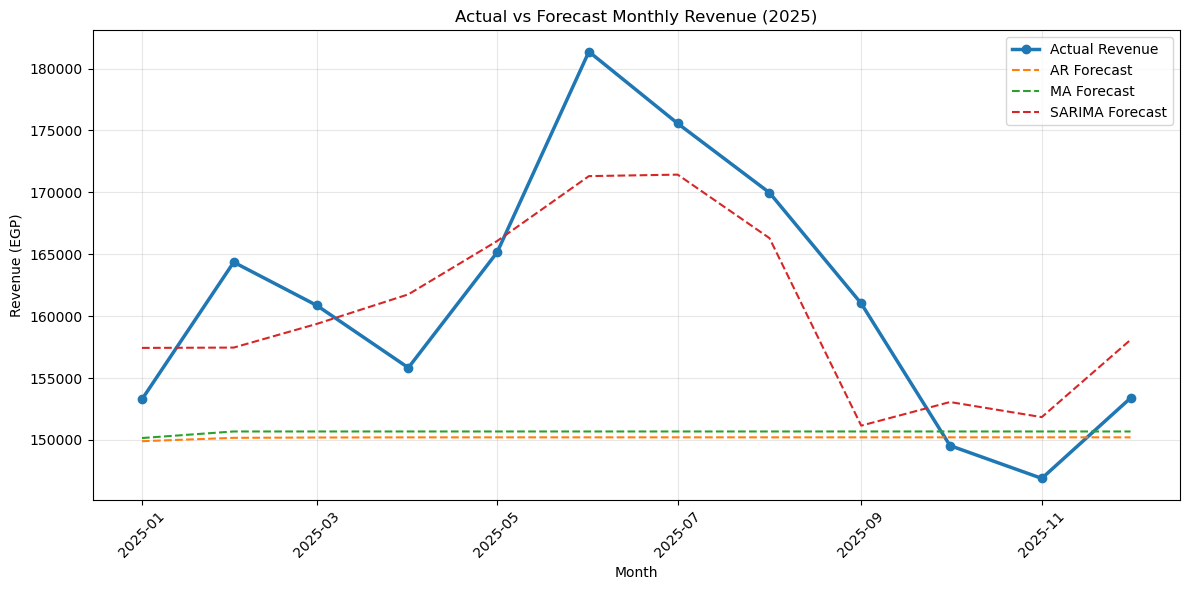

In [71]:
# Part 4- Question 2: Actual vs Forecasted Revenue (2025)

import pandas as pd
import matplotlib.pyplot as plt

# Exstract actual revenue for 2025
actual_2025 = test["Revenue_EGP"] if isinstance(test, pd.DataFrame) else test

# Align actual revenue with forecast dates
actual_2025 = actual_2025.reindex(forecast_2025.index)

# Create comparison chart
plt.figure(figsize=(12,6))

plt.plot(forecast_2025.index, actual_2025,
         label="Actual Revenue", marker="o", linewidth=2.5)

plt.plot(forecast_2025.index, forecast_2025["AR_Forecast"],
        label="AR Forecast", linestyle="--")

plt.plot(forecast_2025.index, forecast_2025["MA_Forecast"],
         label="MA Forecast", linestyle="--")

plt.plot(forecast_2025.index, forecast_2025["SARIMA_Forecast"],
         label="SARIMA Forecast", linestyle="--")

# Chart labels and formatting
plt.title("Actual vs Forecast Monthly Revenue (2025)")
plt.xlabel("Month")
plt.ylabel("Revenue (EGP)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()


In [72]:
# The comparison chart illustrates actual monthly revenue in 2025 alongside forecast sgenerated by the AR, MA, and
# SARIMA models.

# The AR and MA models produced relatively stable forecast sof approximately 150,000 EGP throughout the year,
# failling to capture substantial monthly fluctuations.

# In contrast, the SARIMA model captured some seasonal patterns, particularly the increase in revenue during
# the summer months and the subsequent decline in the fall

# Visually, SARIMA appears to represent the seasonal movements more effectively than the AR and MA models. 
# Howevre, the final model selection will be based on quantitative evaluation using Mean Absolute Error (MAE)
# and Root Mean Squared Error(RMSE)

In [ ]:
# Part 4- Question 3: Evaluate Forecast Accuracy

# Calculate MAE and RMSE for all three models using the same held-out 2025 observations. Present a comparison
# table and identify which model performed best. 


In [75]:
# Part 4- Question 3: Model Evaluation

import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Actual revenue values for 2025 
actual = actual_2025.to_numpy()

# Calculater MAE and RMSE for each model
results = []

for model_name in ["AR", "MA", "SARIMA"]:
    predicted = forecast_2025[f"{model_name}_Forecast"].to_numpy()

    mae = mean_absolute_error(actual, predicted)
    rmse =np.sqrt(mean_squared_error(actual, predicted))

    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse
    })

# Create comparison table
evaluation_df = pd.DataFrame(results)

# Sort model by RMSE (lower is better)
evaluation_df = evaluation_df.sort_values("RMSE").reset_index(drop=True)

# Display comparison table
display(evaluation_df.round(2))

# Identify the best model
best_model =evaluation_df.loc[0, "Model"]

print(f"Best Performing Model: {best_model}")

,Model,MAE,RMSE
0,SARIMA,5024.42,5708.46
1,MA,11617.61,14714.09
2,AR,11920.01,15064.87


Best Performing Model: SARIMA


In [ ]:
# The forecasting performance of the AR, MA< and SARIMA models was evaluated using Mean Absolute Error(MAE)
# and Root Mean Squared Error(RMSE) on the 2025 test dataset.

# The SARIMA model achieved the lowest MAE of 5,024.42 EGP and RMSE of 5,708.46 EGP, outperforming both the 
# AR and MA models. The MA models recorded an RMSE of 14,714.09 EGP, while the AR model had the highest RMSE of 
# 15,064.87 EGP.

# These results indicate that incorporating seasonal patterns substantially improved forecasting accuracy
# for this datsaet. Therefore, SARIMA was selected as the best-performing model for forecasting future
# monthly revenue. 

In [ ]:
# Part 4- Question 4: Forecast Revenue for January- June 2026
# After selecting the winning model, refit it on the full cleaned history(2016-2015) and forecast 
# January-June 2026. Show the six predicted revenue values in a table and draw a final history-plus-future plot 

In [77]:
# Part 4 - Question 4: Forecast Revenue for 2026

import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Use the completed cleaned revenue series (2016-2025)
full_revenue = df["Revenue_EGP"].copy()

# Retrieve the original SARIMA model orders
sarima_order = sarima_model.order
seasonal_order = sarima_model.seasonal_order

# Refit SARIMA using the complete dataset
final_model = SARIMAX(
    full_revenue,
    order=sarima_order,
    seasonal_order=seasonal_order
)

final_fitted = final_model.fit(disp=False)


# Forecast the next six months
future_forecast = final_fitted.forecast(steps=6)

# Create forecast dates
future_dates = pd.date_range(
    start="2026-01-01",
    periods=6,
    freq="MS"
)

# Create forecast table
forecast_2026 = pd.DataFrame({
    "Predicted_Revenue_EGP": future_forecast.to_numpy()
}, index=future_dates)

forecast_2026.index.name = "Date"

display(forecast_2026.round(2))
full_revenue = full_revenue.asfreq("MS")

C:\Users\Sophia\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\Sophia\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


,Predicted_Revenue_EGP
Date,
2026-01-01,161853.55
2026-02-01,164892.74
2026-03-01,165532.49
2026-04-01,165861.56
2026-05-01,170688.33
2026-06-01,176885.25


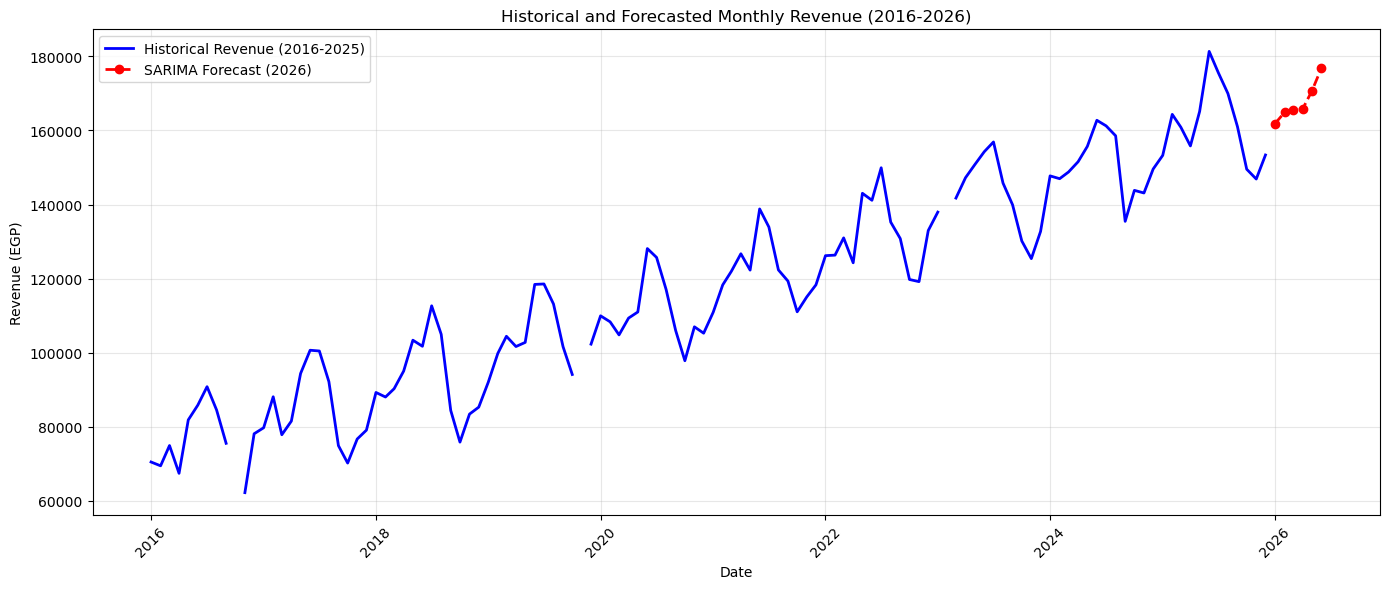

In [80]:
# Part 4- Question 4: Historical and Futrue Revenue Forecast

import matplotlib.pyplot as plt

plt.figure(figsize=(14,6))

# Historical revenue (2016-2025)

plt.plot(
    full_revenue.index,
    full_revenue,
    label="Historical Revenue (2016-2025)",
    color= "blue",
    linewidth=2
)

# SARIMA forecast (January-June 2026)

plt.plot(
    forecast_2026.index,
    forecast_2026["Predicted_Revenue_EGP"],
    label="SARIMA Forecast (2026)",
    color="red",
    linestyle="--",
    marker="o",
    linewidth=2
)

# Add title and labels
plt.title("Historical and Forecasted Monthly Revenue (2016-2026)")
plt.xlabel("Date")
plt.ylabel("Revenue (EGP)")

# Add legend and grid
plt.legend()
plt.grid(True, alpha=0.3)

# Format graph
plt.xticks(rotation=45)
plt.tight_layout()

# Display graph
plt.show()


In [ ]:
# The graph represents historical monthly revenue from January 2016 through December 2025 and the 
# SARIMA revenue forecast sfor January through June 2026. 
# Historical revenue shows a long-term upward trend with noticeable seasonal fluctuations. The SARIMA 
# model forecasts continued revenue growth during the first half of 2026, increasing from 161,853.55 EGP in January
# to 176,885.25 EGP in June

# These projections suggest a positive revenue outlook and may help management make informed decisions about
# budgeting, inventory managemnet, and resource allocation. Howevre, actual revenue may differ from the forecasts
# due to changing business and economic conditions 

In [ ]:
# Part 4- Question 5: Final Conclusion
# Assignment Question: Write a short conclusion: Was the original series stationary? Which transformations were
# needed? Which model won? What business interpretation would you give the futrue forecast?

In [81]:
# Check stationarity using the ADF test

from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(train.dropna())

print("ADF Statistic:", adf_result[0])
print("P-value:", adf_result[1])

ADF Statistic: 0.003664374183390678
P-value: 0.9588340801580341


In [84]:
# ADF Test After First-Order Differencing

from statsmodels.tsa.stattools import adfuller

# First-order differencing
train_diff =train.diff().dropna()

#Perform ADF test
adf_diff = adfuller(train_diff)

print("ADF Statistics:", adf_diff[0])
print("P-value:", adf_diff[1])

if adf_diff[1] <0.05:
    print("Reject H0: The differenced series is stationary.")
else:
    print("Fail to reject h0: Insufficient evidence of stationarity.")

ADF Statistics: -6.7677451014373835
P-value: 2.6901220416728373e-09
Reject H0: The differenced series is stationary.


In [ ]:
# After applying first-order differencing (d=1), the ADF test produced a p-value below 0.05. 
# Therefore, we reject h0 in favor of H1, providing strong evidence that the differenced revenue series is 
# stationary. 